# Learning curve

> How many soils of its own an instrument needs for each method, against memory-based learning on the OSSL library with and without spiking

In [ ]:
#| default_exp learning_curve

In [ ]:
#| export
import numpy as np, pandas as pd
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from soilspecdl.all import predict, ridge_head
from ossl_rt_transfer.pretrain import rt_wns
from ossl_rt_transfer.finetune import plsr, fit_plsr, finetune
from ossl_rt_transfer.recalibrate import linear_recal

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdl.all import get_splitter
from soilspecdata.datasets.ossl import load_ossl
from soilspecdata.datasets.ringtrial import load_ringtrial
from ossl_rt_transfer.data import rt_path, near_dup_groups, load_instruments
from ossl_rt_transfer.pretrain import ossl_xy, load_pretrained, model_dir
from ossl_rt_transfer.finetune import rt_xy, soil_folds, cached, repeat_scores, group_errors, paired_test

The cells that read the ring-trial data are marked `#| rtdata`. The outputs on this page come from a local run.

In `09_all_labs`, each method trained on about 62 soils of one instrument. A lab that adopts a model wants to scan as few of its own soils as it can. This notebook trains each method on 10, 20 and 40 soils of one instrument, and tests it on 30 other soils of the same instrument. The methods are:

- `zero-shot`: the pretrained CNN as it is.
- `slope and bias`: a linear regression of the targets on the zero-shot predictions.
- `head refit`: a ridge regression on the frozen features of the pretrained CNN.
- `fine-tuned`: all of the pretrained CNN fine-tuned on the soils.
- `PLSR`: PLSR trained on the soils only.
- `MBL`: memory-based learning on the OSSL library, with no soils of the instrument.
- `MBL spiked`: MBL with the soils of the instrument added to every neighbourhood.

MBL is the usual method for predictions from a large spectral library. Spiking is the usual way to adapt it to a new instrument or region.

## Memory-based learning

MBL fits a small model for each soil to predict, on its nearest soils in the library. We follow the defaults of the R package `resemble`. The distance is the Mahalanobis distance on the PCA scores of the library, and the local model is a weighted average of PLS fits with 3 to 15 components.

`wapls` gives the weighted average. The weight of the fit with $j$ components is $1/(s_j g_j)$, where $s_j$ is the root mean square of the residual of the query spectrum on $j$ components and $g_j$ is the root mean square of the regression coefficients:

In [ ]:
#| export
def wapls(
    X, # Spectra of the neighbours, one per row
    y, # Targets of the neighbours
    xq, # Spectrum to predict
    min_c=3, # Smallest number of PLS components
    max_c=15, # Largest number of PLS components, at most `len(y) - 1`
)->float: # Prediction for `xq`
    "Weighted average of the predictions of PLS fits with `min_c` to `max_c` components, with the weights of `resemble`"
    max_c = min(max_c, len(y) - 1)
    m = PLSRegression(max_c, scale=False).fit(X, y)
    R, P, Q = m.x_rotations_, m.x_loadings_, m.y_loadings_.ravel()
    xc = xq - m._x_mean
    t, preds, w = xc @ R, [], []
    for j in range(min_c, max_c + 1):
        b = R[:, :j] @ Q[:j]
        res = xc - t[:j] @ P[:, :j].T
        preds.append(y.mean() + xc @ b)
        w.append(1 / (np.sqrt((res**2).mean()) * np.sqrt((b**2).mean())))
    return float(np.dot(w, preds) / np.sum(w))

With a single number of components, `wapls` gives the prediction of PLSR:

In [ ]:
rng = np.random.default_rng(0)
Xs, ys = rng.normal(size=(50, 30)), rng.normal(size=50)
test_close(wapls(Xs, ys, Xs[0], 5, 5), PLSRegression(5, scale=False).fit(Xs, ys).predict(Xs[:1])[0])

`MBL` applies the preprocessing of `plsr` to the library, and finds the neighbours on whitened PCA scores, where the Euclidean distance is the Mahalanobis distance. With spiking, the spiked soils replace the farthest library soils in every neighbourhood:

In [ ]:
#| export
class MBL:
    "Memory-based learning: a `wapls` on the `k` nearest library soils of each query, on whitened PCA scores"
    def __init__(self,
                 X, # Library spectra on `rt_wns`, one per row
                 y, # Library targets
                 k=100, # Number of neighbours
                 n_pcs=20, # Number of PCA components for the distance
                ):
        self.prep = plsr()[:-1].fit(X)
        self.L, self.y, self.k = self.prep.transform(X), y, k
        self.pca = PCA(n_pcs, whiten=True, random_state=0).fit(self.L)
        self.nn = NearestNeighbors().fit(self.pca.transform(self.L))

    def predict(self,
                Xq, # Spectra to predict, one per row
                Xs=None, # Spectra of the spiked soils
                ys=None, # Targets of the spiked soils
               )->np.ndarray: # Predictions
        "Predict `Xq`, with the spiked soils `Xs` in every neighbourhood"
        Q, ns = self.prep.transform(Xq), 0 if ys is None else len(ys)
        _, ix = self.nn.kneighbors(self.pca.transform(Q), n_neighbors=self.k - ns)
        S = None if ns == 0 else self.prep.transform(Xs)
        def one(q, i):
            if ns == 0: return wapls(self.L[i], self.y[i], q)
            return wapls(np.vstack([self.L[i], S]), np.concatenate([self.y[i], ys]), q)
        return np.array([one(q, i) for q, i in zip(Q, ix)])

We choose `k` on the OSSL validation split of `05_pretrain`, on 1,000 of its soils:

In [ ]:
#| rtdata
props = ['potassium_cmolkg', 'clay_perc']
om = load_ossl().mir(650, 4000)
lib = {p: ossl_xy(om, p) for p in props}
def choose_k():
    res = {}
    for p in props:
        X, y, _ = lib[p]
        tr, va, _ = get_splitter(0.9, 0.1, seed=42)(X, y)
        va = np.random.default_rng(0).choice(va, 1000, replace=False)
        for k in [50, 100, 200, 400, 800]:
            pv = MBL(X[tr], y[tr], k=k).predict(X[va])
            res[(p, k)] = 1 - ((pv - y[va])**2).sum() / ((y[va] - y[va].mean())**2).sum()
    return pd.Series(res, name='R²').rename_axis(['property', 'k']).unstack()
ks = cached('mbl_k', choose_k, model_dir()/'learning_curve')
ks.round(3)

,50,100,200,400,800
property,,,,,
clay_perc,0.918,0.931,0.928,0.919,0.905
potassium_cmolkg,0.823,0.833,0.820,0.806,0.785


A neighbourhood of 100 soils is best for both properties. The R² is on the model scale.

In [ ]:
#| rtdata
test_eq(ks.idxmax(axis=1).astype(int).tolist(), [100, 100])

## Training sets

`lc_splits` holds out the same 30 soils for each training size, and nests the training sets: the 10 soils are among the 20, and the 20 among the 40. It adds whole near-duplicate groups, so a training set can have a few more soils than its size:

In [ ]:
#| export
def lc_splits(
    groups:pd.Series, # Near-duplicate group of each soil, indexed by sample id
    sizes=(10, 20, 40), # Smallest numbers of training soils
    repeats=10, # Number of random orders of the groups
)->pd.DataFrame: # One row per repeat and size, with the sample ids of the training and held-out soils
    "Nested training sets of at least `sizes` soils, and the soils that none of them uses, for each repeat"
    out = []
    for r in range(repeats):
        rank = pd.Series(np.random.default_rng(r).permutation(groups.nunique()), index=groups.unique())[groups].values
        order, ends = groups.index[np.argsort(rank, kind='stable')], np.cumsum(np.bincount(rank))
        first = lambda n: list(order[:ends[np.searchsorted(ends, n)]])
        test = list(order[ends[np.searchsorted(ends, max(sizes))]:])
        out += [dict(repeat=r, n=n, train=first(n), test=test) for n in sizes]
    return pd.DataFrame(out)

In [ ]:
g = pd.Series([0, 0, 1, 2, 2, 2, 3, 4, 5, 6], index=list('abcdefghij'))
s = lc_splits(g, sizes=(2, 5), repeats=3)
for _, d in s.groupby('repeat'):
    a, b = d.train
    assert set(a) < set(b) and not set(b) & set(d.test.iloc[0])
    test_eq(len(b) + len(d.test.iloc[0]), 10)
    for t in (a, b): test_eq(set(g[t]) & set(g.drop(t)), set())
s

,repeat,n,train,test
0,0,2,"[i, j]","[c, h, g]"
1,0,5,"[i, j, a, b, d, e, f]","[c, h, g]"
2,1,2,"[c, d, e, f]","[j, g, a, b, i]"
3,1,5,"[c, d, e, f, h]","[j, g, a, b, i]"
4,2,2,"[i, j]","[g, h, a, b, c]"
5,2,5,"[i, j, d, e, f]","[g, h, a, b, c]"


## Runs

`lc_run` trains every method on each training set of `splits`, and predicts the held-out soils. `zero-shot` and `MBL` use no soils of the instrument, and have `n` 0. PLSR chooses its number of components by grouped cross-validation, with at most half the number of training soils:

In [ ]:
#| export
def lc_run(
    model, # Pretrained model
    mbl:MBL, # MBL on the OSSL library
    X, # SNV spectra on `rt_wns`, one per row
    y, # Targets
    ids, # Sample id of each row
    splits:pd.DataFrame, # Training and held-out soils, from `lc_splits`
    groups:pd.Series, # Near-duplicate group of each soil, indexed by sample id
    epochs, # Number of fine-tuning epochs
)->pd.DataFrame: # Held-out predictions
    "Held-out predictions of each method, trained on each training set of `splits`"
    p0, pos, preds = predict(model, X, rt_wns).ravel(), pd.Series(np.arange(len(ids)), index=ids), []
    idx = lambda s: pos.reindex(s).dropna().astype(int).values
    for r, d in splits.groupby('repeat'):
        te = idx(d.test.iloc[0])
        res = {(0, 'zero-shot'): p0[te], (0, 'MBL'): mbl.predict(X[te])}
        for n, tr in zip(d.n, d.train.map(idx)):
            pls = fit_plsr(X[tr], y[tr], groups[ids[tr]].values, max_components=min(15, len(tr) // 2))
            res |= {(n, 'slope and bias'): linear_recal(p0[tr], y[tr], p0[te]),
                    (n, 'head refit'): predict(ridge_head(model, X[tr], y[tr], rt_wns), X[te], rt_wns).ravel(),
                    (n, 'fine-tuned'): finetune(model, X, y, tr, te, epochs, seed=r)[0],
                    (n, 'PLSR'): pls.predict(X[te]).ravel(),
                    (n, 'MBL spiked'): mbl.predict(X[te], X[tr], y[tr])}
        preds += [pd.DataFrame({'n': n, 'method': m, 'repeat': r, 'sample_id': ids[te], 'y': y[te], 'pred': p})
                  for (n, m), p in res.items()]
    return pd.concat(preds, ignore_index=True)

Each method runs on the 21 instruments, with the starting models and numbers of fine-tuning epochs of `09_all_labs`:

In [ ]:
#| rtdata
import warnings
rt = load_ringtrial(rt_path())
groups = pd.Series(near_dup_groups(rt['KSSL']), index=rt['KSSL'].sample_ids)
insts, start = list(rt.keys()), 'snv_ep80'
splits = lc_splits(groups)
n_epochs = {p: int(cached(f'epochs_{p}', None)['not augmented 80'].idxmin()) for p in props}
preds = []
for p in props:
    m, mbl = load_pretrained(f'ossl_{p}_{start}'), MBL(*lib[p][:2], k=100)
    for i in insts:
        X, y, ids = rt_xy(rt[i], p)
        def run():
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', UserWarning)
                return lc_run(m, mbl, X, y, ids, splits, groups, n_epochs[p])
        preds.append(cached(f'lc_{i}_{p}', run, model_dir()/'learning_curve').assign(instrument=i, property=p))
preds = pd.concat(preds, ignore_index=True)
test_eq(preds.instrument.nunique(), 21)
splits.assign(train=splits.train.map(len), test=splits.test.map(len)).groupby('n')[['train', 'test']].agg(['min', 'max'])

train     test    
     min max  min max
n                    
10    10  14   30  30
20    20  21   30  30
40    40  40   30  30

## Results

R² on the original scale, for each repeat of 30 held-out soils, then the mean over the repeats. The table gives its median over the 21 instruments. The column `62 (09)` comes from the 10-fold cross-validation of `09_all_labs`, with about 62 training soils and other held-out soils:

In [ ]:
#| rtdata
keys = ['instrument', 'property', 'method', 'n']
scores = repeat_scores(preds, keys).groupby(keys).mean()
def scores_09():
    d = pd.concat([cached(f, None).assign(instrument=i, property=p) for p in props for i in insts
                   for f in (f'recal_{i}_{p}_{start}', f'plsr_{i}_{p}', f'cnn_{i}_{p}_{start}')], ignore_index=True)
    return repeat_scores(d, keys[:3]).groupby(keys[:3]).mean()['R²']
r2 = scores['R²'].unstack('n')
methods = ['zero-shot', 'MBL', 'slope and bias', 'head refit', 'fine-tuned', 'PLSR', 'MBL spiked']
med = r2.join(scores_09().rename('62 (09)')).groupby(['property', 'method']).median().reindex(methods, level='method')
med.round(2)

0    10    20    40  62 (09)
property         method                                         
clay_perc        zero-shot       0.50   NaN   NaN   NaN     0.57
                 MBL             0.53   NaN   NaN   NaN      NaN
                 slope and bias   NaN  0.59  0.63  0.63     0.67
                 head refit       NaN  0.55  0.68  0.74     0.82
                 fine-tuned       NaN  0.61  0.69  0.77     0.83
                 PLSR             NaN -0.04  0.32  0.49     0.59
                 MBL spiked       NaN  0.69  0.74  0.79      NaN
potassium_cmolkg zero-shot      -0.40   NaN   NaN   NaN    -0.24
                 MBL            -0.38   NaN   NaN   NaN      NaN
                 slope and bias   NaN  0.23  0.35  0.42     0.49
                 head refit       NaN  0.25  0.38  0.46     0.58
                 fine-tuned       NaN  0.34  0.41  0.48     0.63
                 PLSR             NaN -0.01 -0.16  0.25     0.22
                 MBL spiked       NaN  0.19  0.29  0.39      NaN

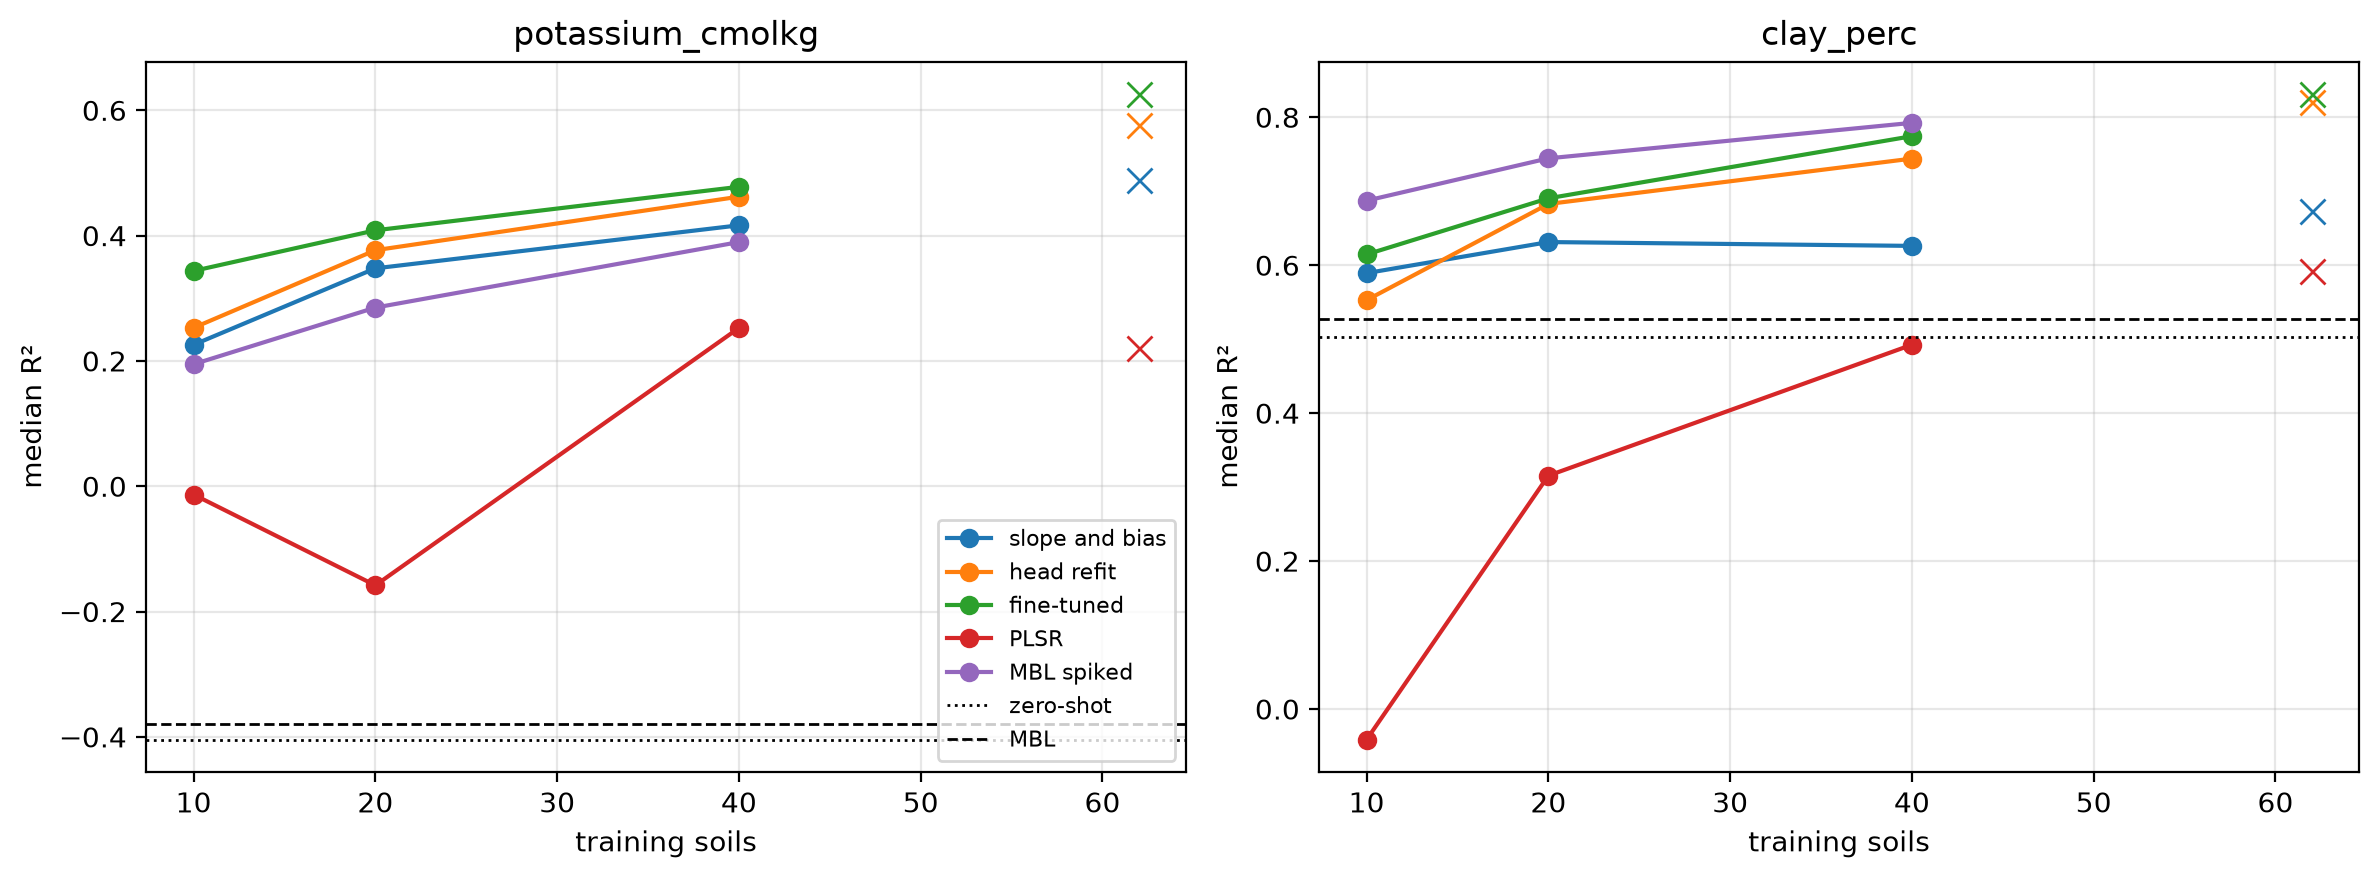

In [ ]:
#| rtdata
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, p in zip(axs, props):
    t = med.loc[p]
    for m in methods[2:]:
        l, = ax.plot([10, 20, 40], t.loc[m, [10, 20, 40]], 'o-', label=m)
        ax.plot(62, t.loc[m, '62 (09)'], 'x', color=l.get_color(), ms=9)
    for m, ls in [('zero-shot', ':'), ('MBL', '--')]: ax.axhline(t.loc[m, 0], color='k', ls=ls, lw=1, label=m)
    ax.set_title(p); ax.set_xlabel('training soils'); ax.set_ylabel('median R²'); ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
plt.tight_layout()

R² of each instrument with 20 training soils:

In [ ]:
#| rtdata
inst_info = load_instruments()[['cluster', 'manufacturer']]
def table(p, n=20):
    t = r2.xs(p, level='property')
    t = pd.concat([t[0].unstack()[['zero-shot', 'MBL']], t[n].unstack()[methods[2:]]], axis=1)
    return inst_info.join(t, how='right').sort_values(['cluster', 'fine-tuned'], ascending=[True, False])
table('potassium_cmolkg').round(2)

,cluster,manufacturer,zero-shot,MBL,slope and bias,head refit,fine-tuned,PLSR,MBL spiked
instrument,,,,,,,,,
UWisc_fine,1.0,Bruker,-0.09,0.08,0.09,0.10,0.36,-0.22,0.13
Argonne,2.0,PerkinElmer,0.16,0.24,0.34,0.37,0.51,-0.18,0.45
UGhent,2.0,Agilent,-1.65,-0.01,0.32,0.39,0.50,0.15,0.38
OSU,2.0,Thermo Fisher,-0.97,-0.44,0.25,0.29,0.37,-0.29,0.01
IAEA_aug2022,2.0,Thermo Fisher,-2.85,-1.85,0.34,0.04,0.26,-0.41,-0.16
UIUC,2.0,Thermo Fisher,-3.66,-2.05,-0.32,-0.25,0.24,0.02,-0.28
Lesotho,2.0,PerkinElmer,-1.74,-4.65,-0.25,-0.14,-0.28,-0.14,-0.41
ETH_alpha_1,3.0,Bruker,-0.63,-1.09,0.43,0.40,0.46,-0.33,0.05
Agrocares,3.0,Bruker,-0.01,-0.78,0.37,0.38,0.46,-0.54,0.41


In [ ]:
#| rtdata
table('clay_perc').round(2)

,cluster,manufacturer,zero-shot,MBL,slope and bias,head refit,fine-tuned,PLSR,MBL spiked
instrument,,,,,,,,,
UWisc_fine,1.0,Bruker,0.38,0.13,0.51,0.61,0.65,0.44,0.25
Argonne,2.0,PerkinElmer,0.64,0.66,0.65,0.68,0.70,0.36,0.74
OSU,2.0,Thermo Fisher,0.42,0.46,0.43,0.46,0.66,0.37,0.70
UGhent,2.0,Agilent,0.24,0.26,0.55,0.59,0.63,0.30,0.54
UIUC,2.0,Thermo Fisher,-0.09,-0.81,0.11,-0.01,0.51,0.37,-0.08
Lesotho,2.0,PerkinElmer,-0.27,-1.73,-0.04,0.01,0.26,-0.16,0.12
IAEA_aug2022,2.0,Thermo Fisher,-2.56,-0.23,0.15,0.26,-0.26,0.08,0.40
Woodwell_vertex,3.0,Bruker,0.68,0.65,0.65,0.73,0.75,0.23,0.81
Woodwell_alpha,3.0,Bruker,0.74,0.51,0.73,0.73,0.74,0.32,0.74


Paired Wilcoxon tests on the mean squared error of each near-duplicate group, on the model scale, over its held-out soils and the repeats. Each count is the number of instruments where one method has a significantly smaller error, at p < 0.05:

In [ ]:
#| rtdata
ge = group_errors(preds, groups, keys)
pairs = [('fine-tuned', 'MBL spiked'), ('fine-tuned', 'slope and bias'), ('fine-tuned', 'head refit'), ('MBL spiked', 'slope and bias')]
tests = pd.DataFrame({(p, n, a, b, i): paired_test(ge.loc[(i, p, a, n)], ge.loc[(i, p, b, n)])
                      for p in props for n in (10, 20, 40) for a, b in pairs for i in insts}).T
tests.index.names = ['property', 'n', 'A', 'B', 'instrument']
sig = tests.p < 0.05
pd.DataFrame({'A wins': sig & (tests.A_better > 0.5), 'B wins': sig & (tests.A_better < 0.5)}).groupby(['property', 'A', 'B', 'n']).sum().unstack('n')

A wins        B wins      
n                                              10 20  40     10 20 40
property         A          B                                        
clay_perc        MBL spiked slope and bias      7  9  13      0  0  0
                 fine-tuned MBL spiked          0  0   1      8  7  2
                            head refit          7  5   8      5  5  2
                            slope and bias      4  3  12      6  2  0
potassium_cmolkg MBL spiked slope and bias      4  3   2      4  2  1
                 fine-tuned MBL spiked          7  6   4      0  0  0
                            head refit         10  6   7      0  1  0
                            slope and bias      7  7   9      0  0  0

### What the learning curve shows

For clay, spiked MBL has the best median R² at every size: 0.69 with 10 soils, 0.74 with 20 and 0.79 with 40. Fine-tuning gives 0.61, 0.69 and 0.77. The paired tests favour spiked MBL on 8 instruments with 10 soils and on 2 with 40, and fine-tuning on 1 with 40. Spiked MBL beats the slope and bias on 7 to 13 instruments, and never loses to it.

For K, fine-tuning has the best median R² at every size: 0.34 with 10 soils, 0.41 with 20 and 0.48 with 40. Spiked MBL gives 0.19, 0.29 and 0.39. The paired tests favour fine-tuning over spiked MBL on 4 to 7 instruments, and never the reverse. Fine-tuning also beats the head refit on 10 instruments with 10 soils.

Without soils of the instrument, MBL and the zero-shot CNN have about the same median R²: 0.53 and 0.50 for clay, and -0.38 and -0.40 for K. MBL needs the spiked soils for most of its gain.

Spiked MBL fails where an instrument differs most from the library. With 10 soils for K, its R² is below zero on 8 instruments, such as USP (-0.57), IAEA (-0.48) and UIUC (-0.40). Fine-tuning is below zero only on Lesotho (-0.44). For clay, each method is at or below zero on 2 instruments: spiked MBL on UIUC (-0.36) and Lesotho (-0.49), and fine-tuning on IAEA (-0.42) and Lesotho (-0.00).

With 40 soils, every method is still below its result from about 62 soils in `09_all_labs`. Fine-tuning goes from 0.77 to 0.83 for clay, and from 0.48 to 0.63 for K. The held-out soils differ between the two designs, so the comparison is approximate. On the cluster 4 Bruker instruments, the head refit with 40 soils is the best method for clay, with R² 0.92 on KSSL, 0.91 on CSU_IL and 0.90 on MSU.

### What this suggests

For clay, spiking 10 to 20 soils into MBL on the OSSL library gives most of what fine-tuning gives with 40, and costs much less. For K, fine-tuning is the better method at every size, and K needs more than 40 soils. Both methods fail on some instruments with 10 soils, and the instruments differ between them.

### Limits

- MBL uses the defaults of `resemble`, with `k` chosen on the OSSL validation split. The spiked soils have no extra weight.
- Fine-tuning uses the numbers of epochs of `09_all_labs`, chosen with about 62 soils. With fewer soils, it makes fewer gradient steps.
- Each repeat scores 30 held-out soils, so the R² of one instrument and one repeat is noisy.